# Módulo 0. Comprender y preparar los datos de Olist

**Pregunta del proyecto:** al cierre de un día, ¿cuántas órdenes de compra recibirá Olist cada uno de los próximos 28 días?

Desarrollamos el Módulo 0 y el Módulo B del taller. La unidad es una **orden de compra**; la fecha relevante es `order_purchase_timestamp`. Los modelos de clasificación, segmentación y la extensión opcional por categorías o estados quedan fuera del alcance.

Este notebook explica las tablas, comprueba su calidad y construye una serie diaria. El notebook `B_series_01_exploracion` estudia los patrones temporales y `B_series_02_modelado` entrena y evalúa los modelos. Ejecuta las celdas en orden; los resultados están guardados para leerlos también en GitHub.

In [1]:
# La ruta funciona tanto al abrir notebooks/ como desde la raíz del proyecto.
from pathlib import Path
import sys, json
ROOT=Path.cwd() if (Path.cwd()/'sql').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.configuracion import INICIO, CORTE, FIN, SELECCION, CALIBRACION, PRUEBA, NIVEL, particiones
from src.datos import conectar, consultar, preparar, exportar
pd.set_option('display.max_columns',20)
pd.set_option('display.max_rows',35)
# Estilo común de figuras (src/estilo.py): Source Sans 3, grilla tenue y colores fijos.
from src.estilo import aplicar_estilo, figura, mostrar
aplicar_estilo()
(ROOT/'resultados').mkdir(exist_ok=True)
(ROOT/'documentacion/figuras').mkdir(parents=True,exist_ok=True)
con=conectar()  # read_only=True: el análisis no escribe en la base original.


## 1. Granularidad: qué representa una fila

- `orders`: una orden identificada por `order_id`.
- `order_items`: un artículo dentro de una orden; la llave es `(order_id, order_item_id)`.
- `order_payments`: un registro de pago; puede haber varios por orden.
- `order_reviews`: reseñas; un `review_id` repetido merece inspección, pero no prueba que dos filas completas sean idénticas.
- `customers`: `customer_id` identifica el registro asociado a una compra. `customer_unique_id` permite reconocer al mismo comprador entre órdenes.
- `geolocation`: varias coordenadas pueden compartir un prefijo postal.

**Ejemplo:** una compra de tres artículos sigue siendo una sola orden. Contar filas después de unir órdenes con artículos la contaría tres veces. Si además tiene dos pagos, una unión directa puede generar seis filas. Por eso el objetivo sale directamente de `orders`.

In [2]:
# SQL consulta las llaves reales y cuantifica el efecto de uniones 1:N.
tablas=consultar(con,'tablas.sql'); exportar(tablas,'tablas')
mostrar(tablas,'Tablas disponibles en olist.duckdb y número de filas',
        'Una tabla por archivo del dataset, cargadas sin limpiar.')
llaves=consultar(con,'llaves.sql'); exportar(llaves,'llaves')
mostrar(llaves,'Unicidad de la llave candidata de cada tabla',
        'repetidos > 0 indica que esa columna no identifica una fila por sí sola.')
relaciones=consultar(con,'relaciones.sql'); exportar(relaciones,'relaciones')
mostrar(relaciones,'Filas que produce unir orders con ítems y pagos (relaciones 1:N)',
        'Si filas_join_* supera a ordenes, contar filas después del JOIN sobrestima las compras.')
assert llaves.loc[llaves.tabla.eq('orders'),'repetidos'].iloc[0]==0


■ Tablas disponibles en olist.duckdb y número de filas
  Una tabla por archivo del dataset, cargadas sin limpiar.


,tabla,filas
0,orders,99441
1,customers,99441
2,order_items,112650
3,order_payments,103886
4,order_reviews,99224
5,products,32951
6,sellers,3095
7,category_translation,71
8,geolocation,1000163



■ Unicidad de la llave candidata de cada tabla
  repetidos > 0 indica que esa columna no identifica una fila por sí sola.


,tabla,llave_candidata,filas,distintos,repetidos,nulos
0,orders,order_id,99441,99441,0,0
1,customers,customer_id,99441,99441,0,0
2,sellers,seller_id,3095,3095,0,0
3,products,product_id,32951,32951,0,0
4,order_items,"order_id,order_item_id",112650,112650,0,0
5,order_payments,"order_id,payment_sequential",103886,103886,0,0
6,order_reviews,review_id,99224,98410,814,0
7,category_translation,product_category_name,71,71,0,0
8,geolocation,geolocation_zip_code_prefix,1000163,19015,981148,0



■ Filas que produce unir orders con ítems y pagos (relaciones 1:N)
  Si filas_join_* supera a ordenes, contar filas después del JOIN sobrestima las compras.


,ordenes,filas_join_items,filas_join_pagos,filas_join_items_y_pagos,ordenes_varios_items,ordenes_varios_pagos,ordenes_varias_resenas,sin_cliente
0,99441,113425.0,103887.0,118434.0,9803,2961,547,0


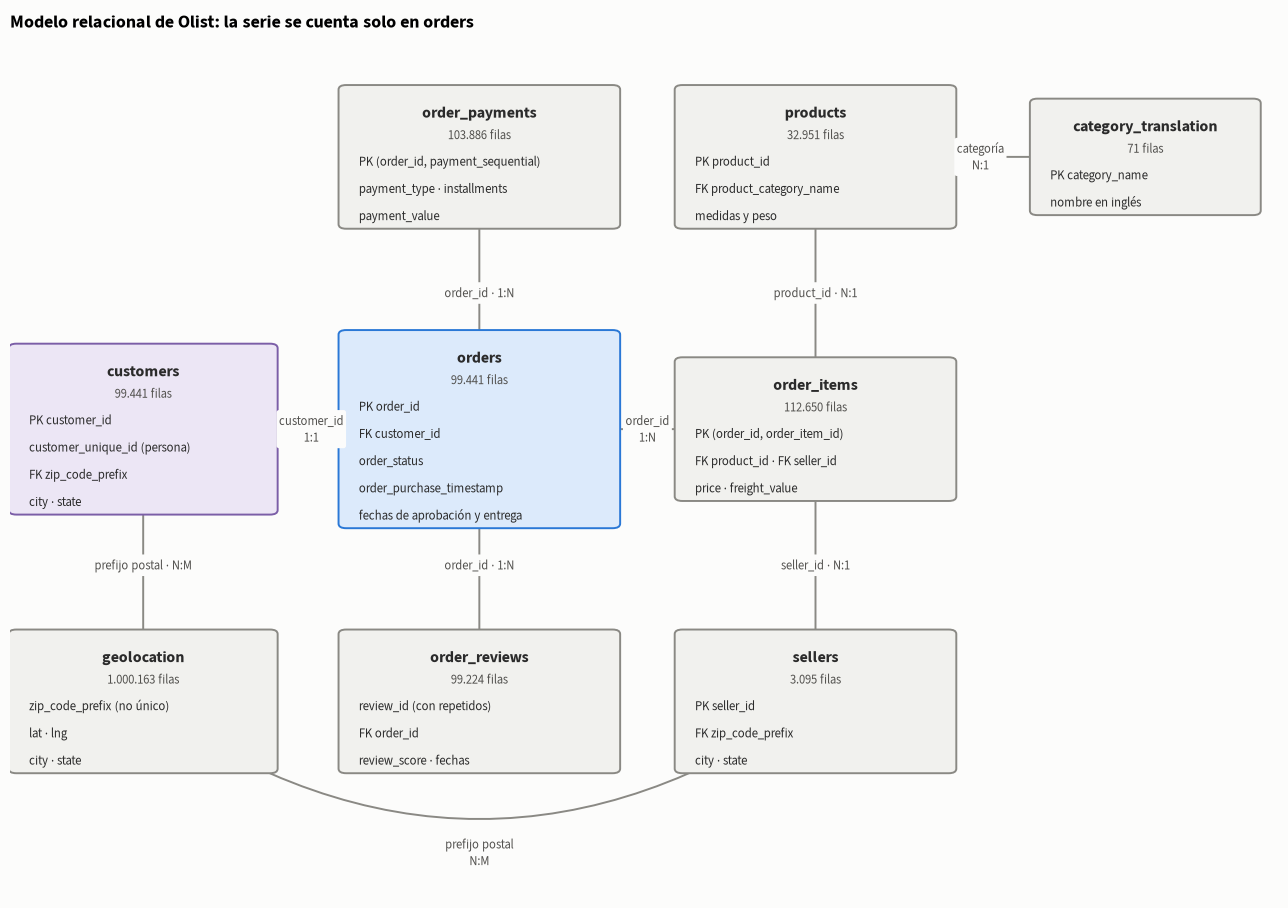

In [3]:

# Modelo relacional: cada caja es una tabla (filas contadas en SQL); cada línea, una llave de unión.
from matplotlib.patches import FancyBboxPatch
filas=tablas.set_index('tabla').filas
# (x, y, ancho, campos). PK = llave primaria; FK = llave foránea.
CAJAS={'orders':(.37,.50,.21,['PK order_id','FK customer_id','order_status','order_purchase_timestamp','fechas de aprobación y entrega']),
       'customers':(.105,.50,.20,['PK customer_id','customer_unique_id (persona)','FK zip_code_prefix','city · state']),
       'order_items':(.635,.50,.21,['PK (order_id, order_item_id)','FK product_id · FK seller_id','price · freight_value']),
       'order_payments':(.37,.86,.21,['PK (order_id, payment_sequential)','payment_type · installments','payment_value']),
       'order_reviews':(.37,.14,.21,['review_id (con repetidos)','FK order_id','review_score · fechas']),
       'products':(.635,.86,.21,['PK product_id','FK product_category_name','medidas y peso']),
       'category_translation':(.895,.86,.17,['PK category_name','nombre en inglés']),
       'sellers':(.635,.14,.21,['PK seller_id','FK zip_code_prefix','city · state']),
       'geolocation':(.105,.14,.20,['zip_code_prefix (no único)','lat · lng','city · state'])}
RELACIONES=[('customers','orders','customer_id · 1:1',0),('orders','order_items','order_id · 1:N',0),
            ('orders','order_payments','order_id · 1:N',0),('orders','order_reviews','order_id · 1:N',0),
            ('order_items','products','product_id · N:1',0),('products','category_translation','categoría · N:1',0),
            ('order_items','sellers','seller_id · N:1',0),('customers','geolocation','prefijo postal · N:M',0),
            ('sellers','geolocation','prefijo postal · N:M',-.35)]
fig,ax=plt.subplots(figsize=(13,9.2)); ax.set_xlim(0,1); ax.set_ylim(-.12,1.02); ax.axis('off')
for a,b,texto,curva in RELACIONES:
    (xa,ya,*_),(xb,yb,*_)=CAJAS[a],CAJAS[b]
    ax.annotate('',xy=(xb,yb),xytext=(xa,ya),zorder=1,
                arrowprops=dict(arrowstyle='-',color='#8a8984',lw=1.4,connectionstyle=f'arc3,rad={curva}'))
    xm,ym=((xa+xb)/2,(ya+yb)/2) if not curva else ((xa+xb)/2,-.06)
    # En las uniones horizontales el espacio es estrecho: la etiqueta va en dos líneas.
    ax.text(xm,ym,texto.replace(' · ','\n') if ya==yb else texto,ha='center',va='center',fontsize=9,color='#52514e',zorder=3,
            bbox=dict(boxstyle='round,pad=.2',fc='#fcfcfb',ec='none'))
for nombre,(x,y,ancho,campos) in CAJAS.items():
    color={'orders':('#dceafb','#2a78d6'),'customers':('#ece6f5','#7b5ea7')}.get(nombre,('#f1f1ee','#8a8984'))
    alto=.07+.036*len(campos)
    ax.add_patch(FancyBboxPatch((x-ancho/2,y-alto/2),ancho,alto,boxstyle='round,pad=.006',fc=color[0],ec=color[1],lw=1.4,zorder=2))
    ax.text(x,y+alto/2-.03,nombre,ha='center',va='center',fontsize=11.5,fontweight='bold',color='#2b2b2b',zorder=4)
    ax.text(x,y+alto/2-.06,f'{int(filas[nombre]):,} filas'.replace(',','.'),ha='center',va='center',fontsize=9,color='#52514e',zorder=4)
    for i,campo in enumerate(campos):
        ax.text(x-ancho/2+.01,y+alto/2-.095-.036*i,campo,ha='left',va='center',fontsize=9.2,color='#2b2b2b',zorder=4)
ax.set_title('Modelo relacional de Olist: la serie se cuenta solo en orders',loc='left',fontsize=13)
figura('modelo_relacional')



**Lectura del diagrama.** `orders` es el centro del modelo: cada orden tiene un `order_id` único y se une 1:1 con su cliente, y 1:N con ítems, pagos y reseñas. Los ítems llevan al producto, a su categoría y al vendedor. Los prefijos postales de clientes y vendedores se relacionan N:M con `geolocation`, porque un prefijo tiene muchas coordenadas.

**Decisiones que se derivan del diagrama**

- **La serie del Módulo B se cuenta solo en `orders`** (azul), una fila por orden y por su fecha de compra. No se une con ítems ni pagos: esas relaciones 1:N multiplican filas (118.434 filas para 99.441 órdenes en la tabla anterior) y contarían varias veces la misma compra.
- **`customers`** (violeta) solo se usa en la exploración geográfica. `customer_id` es una clave por orden; la persona real es `customer_unique_id` (§3).
- **`geolocation` no tiene llave única.** Se agrega por prefijo antes de cualquier unión para no duplicar clientes.
- **`order_reviews` repite `review_id`**, así que tampoco sirve como llave por sí sola.


## 2. Calidad y decisiones de tratamiento

Comprobamos fechas imposibles, ausencia de ítems/pagos, valores faltantes, relaciones huérfanas y conciliación monetaria. Primero sumamos ítems y pagos **por separado por orden**; después los unimos.

Una entrega ausente puede ser coherente con una orden cancelada o pendiente. Una discrepancia monetaria requiere investigación, pero no significa que la compra nunca ocurrió. No eliminamos órdenes por problemas que no invalidan su fecha ni su identidad. La serie incluye todos los estados finales porque el objetivo es demanda recibida, no entregas completadas.

In [4]:
# Cada tabla queda exportada para que la conclusión pueda verificarse.
for archivo,nombre,titulo,nota in [
    ('calidad.sql','calidad','Calidad de órdenes: fechas, ítems, pagos y conciliación monetaria',
     'Conteo de órdenes que presentan cada problema.'),
    ('calidad_extra.sql','calidad_extra','Faltantes y relaciones huérfanas entre tablas',
     'Nulos en fechas y categorías, prefijos sin geolocalización e ítems sin orden/producto/vendedor.'),
    ('estados.sql','estados','Órdenes por estado final (order_status)',None)]:
    tabla=consultar(con,archivo)
    mostrar(tabla,titulo,nota); exportar(tabla,nombre)
calidad=consultar(con,'calidad.sql').iloc[0]
assert calidad.compras_sin_fecha==0 and calidad.ids_duplicados==0
print(f"\nHay {int(calidad.ordenes):,} órdenes; {int(calidad.sin_items)} sin ítems y {int(calidad.sin_pagos)} sin pagos.")
print('Estas ausencias se documentan y no invalidan por sí mismas el conteo de compras.')


■ Calidad de órdenes: fechas, ítems, pagos y conciliación monetaria
  Conteo de órdenes que presentan cada problema.


,ordenes,ids_duplicados,compras_sin_fecha,entrega_antes_compra,aprobacion_antes_compra,sin_items,sin_pagos,diferencia_pago_mayor_2_centavos
0,99441,0,0,0,0,775,1,280



■ Faltantes y relaciones huérfanas entre tablas
  Nulos en fechas y categorías, prefijos sin geolocalización e ítems sin orden/producto/vendedor.


,aprobacion_nula,entrega_nula,categoria_nula,productos_sin_traduccion,clientes_sin_geolocalizacion,vendedores_sin_geolocalizacion,items_huerfanos,items_sin_producto,items_sin_vendedor
0,160,2965,610,13,278,7,0,0,0



■ Órdenes por estado final (order_status)


,order_status,ordenes
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2



Hay 99,441 órdenes; 775 sin ítems y 1 sin pagos.
Estas ausencias se documentan y no invalidan por sí mismas el conteo de compras.


## 3. Identidad del cliente: `customer_id` frente a `customer_unique_id`

La tabla `customers` tiene dos identificadores que parecen equivalentes pero no lo son:

- **`customer_id`**: identificador del cliente **dentro de una orden**. Olist genera uno nuevo cada vez que se hace una compra, así que funciona como una llave de la orden más que de la persona.
- **`customer_unique_id`**: identificador de la **persona** que compra. Se repite cuando la misma persona vuelve a comprar.

La consulta `identidad_cliente.sql` verifica esta diferencia con los datos: cuántos `customer_id` aparecen en más de una orden, cuántas personas reales hay y cuántas acumulan varios `customer_id`.

In [5]:
# La comparación de identificadores se resuelve en SQL; aquí solo se muestra y se verifica.
identidad=consultar(con,'identidad_cliente.sql'); exportar(identidad,'identidad_cliente')
mostrar(identidad.T.rename(columns={0:'valor'}),'Identidad del cliente: customer_id frente a customer_unique_id',
        'Tabla traspuesta para leer un indicador por fila.')
fila=identidad.iloc[0]
assert fila.customer_id_con_varias_ordenes==0  # customer_id es 1:1 con la orden
print(f"\nCada customer_id corresponde a una sola orden; las {int(fila.registros_customers):,} filas de customers "
      f"representan a {int(fila.personas_customer_unique_id):,} personas.")
print(f"{int(fila.personas_con_varios_customer_id):,} personas tienen más de un customer_id (hasta "
      f"{int(fila.max_customer_id_por_persona)}): agruparlas por customer_id las contaría como clientes distintos.")


■ Identidad del cliente: customer_id frente a customer_unique_id
  Tabla traspuesta para leer un indicador por fila.


,valor
registros_customers,99441.0
customer_id_distintos,99441.0
customer_id_con_varias_ordenes,0.0
personas_customer_unique_id,96096.0
personas_con_varios_customer_id,2997.0
max_customer_id_por_persona,17.0
ordenes_de_personas_recurrentes,6342.0
personas_en_varios_estados,39.0
personas_en_varios_prefijos,250.0



Cada customer_id corresponde a una sola orden; las 99,441 filas de customers representan a 96,096 personas.
2,997 personas tienen más de un customer_id (hasta 17): agruparlas por customer_id las contaría como clientes distintos.


**Lectura de la tabla.** Ningún `customer_id` aparece en más de una orden: es, en la práctica, una segunda llave de `orders`. Las 99.441 filas de `customers` corresponden a **96.096 personas**. Solo **2.997 personas (3,1 %)** tienen más de un `customer_id`, es decir, compraron más de una vez; una llega a 17 compras. Esas personas recurrentes hacen 6.342 órdenes (6,4 % del total). Además, 39 personas aparecen en más de un estado y 250 en más de un prefijo postal: la dirección pertenece a la **orden**, no a la persona.

**Consecuencias para el Módulo A (entregas tardías, unidad = orden).**
- Para variables de la orden, como estado de destino o distancia cliente–vendedor, se une por `customer_id`: así se usa la dirección de **esa** compra, aunque la persona se haya mudado.
- Para el historial del cliente (compras previas, retrasos sufridos antes) hay que agrupar por `customer_unique_id`. Agrupando por `customer_id`, todas las órdenes tendrían cero compras previas y la variable no aportaría nada.
- Ese historial debe calcularse **solo con órdenes entregadas antes de la aprobación** de la orden evaluada, para no filtrar información del futuro. Aun así, el 97 % de las órdenes viene de personas sin historial, así que la variable aporta poco y conviene marcar a los compradores nuevos.

**Consecuencias para el Módulo C (segmentación, unidad = persona).**
- La unidad debe ser `customer_unique_id`. Con `customer_id` habría 99.441 "clientes" con frecuencia 1, y el RFM quedaría degenerado: cada fila sería una sola compra.
- Incluso con la llave correcta, la frecuencia casi no varía (97 % compra una vez). Conviene tratarla como indicador binario (recurrente o no) y apoyar la segmentación en recencia, valor y comportamiento.
- Para la región de una persona con varias direcciones hay que fijar una regla; en la sección 6.1 se usa la de su compra más reciente.

**Para este trabajo (Módulo B).** La serie cuenta **órdenes**, así que la identidad no altera la demanda diaria. Sí importa en la exploración de clientes de la sección 6, que usa `customer_unique_id`.

## 4. Cobertura: distinguir ausencia de registros y demanda cero

Antes de entrenar debemos definir qué tramo representa una actividad suficientemente continua. La cobertura continua va de **2017-02-01 a 2018-08-21**. La actividad inicial es escasa; en el extremo final hay un descenso de registros y observaciones aisladas posteriores.

Este corte es una decisión de cobertura. Las tablas por sí solas **no demuestran** si el descenso final es comercial, administrativo o una limitación de extracción. Por tanto, los resultados son condicionales al tramo elegido. No se elige el corte buscando el menor error.

La inspección de cobertura usa toda la base para definir el universo del ejercicio; el diagnóstico que informa los modelos se limitará al historial anterior a la primera validación. Como estas fechas ya se han examinado, la evaluación completa es retrospectiva.


■ Cobertura mensual de toda la base
  Órdenes y días con compras por mes; un mes con pocos días activos no es un mes de demanda normal.


,mes,ordenes,dias_con_compras,dias_del_mes,primera_compra,ultima_compra
0,2016-09-01,4,4,30,2016-09-04 21:15:19,2016-09-15 12:16:38
1,2016-10-01,324,10,31,2016-10-02 22:07:52,2016-10-22 08:25:27
2,2016-11-01,0,0,30,NaT,NaT
3,2016-12-01,1,1,31,2016-12-23 23:16:47,2016-12-23 23:16:47
4,2017-01-01,800,27,31,2017-01-05 11:56:06,2017-01-31 23:37:58
5,2017-02-01,1780,28,28,2017-02-01 00:04:17,2017-02-28 23:47:08
6,2017-03-01,2682,31,31,2017-03-01 00:01:30,2017-03-31 23:54:45
7,2017-04-01,2404,30,30,2017-04-01 00:54:10,2017-04-30 23:48:13
8,2017-05-01,3700,31,31,2017-05-01 01:18:22,2017-05-31 22:59:52
9,2017-06-01,3245,30,30,2017-06-01 00:05:38,2017-06-30 23:20:08


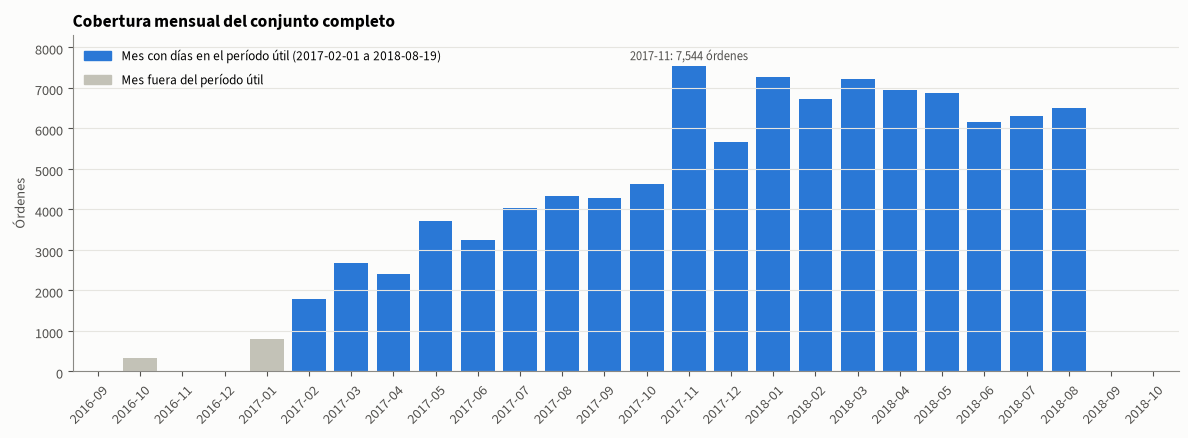

In [6]:
# El calendario mensual incluye incluso meses sin órdenes.
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
cobertura=consultar(con,'cobertura.sql'); exportar(cobertura,'cobertura_mensual')
cobertura['mes']=pd.to_datetime(cobertura.mes)
mostrar(cobertura,'Cobertura mensual de toda la base',
        'Órdenes y días con compras por mes; un mes con pocos días activos no es un mes de demanda normal.')

# Barras por mes: posiciones enteras y etiquetas 'AAAA-MM' ancladas por su extremo derecho,
# así cada etiqueta rotada termina justo debajo de su barra (sin hora en el eje).
dentro=(cobertura.mes>=pd.Timestamp(INICIO).replace(day=1))&(cobertura.mes<=pd.Timestamp(FIN))
posiciones=np.arange(len(cobertura))
fig,ax=plt.subplots(figsize=(12,4.5))
ax.bar(posiciones,cobertura.ordenes,width=0.8,color=np.where(dentro,'#2a78d6','#c3c2b7'))
ax.set_xticks(posiciones)
ax.set_xticklabels(cobertura.mes.dt.strftime('%Y-%m'),rotation=45,ha='right',rotation_mode='anchor')
ax.set_xlim(-0.6,len(cobertura)-0.4); ax.set_ylim(0,cobertura.ordenes.max()*1.1); ax.grid(axis='x',visible=False)
pico=cobertura.ordenes.idxmax()
ax.annotate(f"{cobertura.mes[pico]:%Y-%m}: {cobertura.ordenes[pico]:,} órdenes",(pico,cobertura.ordenes[pico]),
            xytext=(0,4),textcoords='offset points',ha='center',fontsize=9,color='#52514e')
ax.set(title='Cobertura mensual del conjunto completo',ylabel='Órdenes')
ax.legend(handles=[Patch(color='#2a78d6',label=f'Mes con días en el período útil ({INICIO} a {FIN})'),
                   Patch(color='#c3c2b7',label='Mes fuera del período útil')],frameon=False,loc='upper left')
figura('cobertura_mensual')

**Lectura del gráfico.** Cada barra es el total de órdenes de un mes de toda la base; en azul, los meses que entran en el período útil.

- **Inicio irregular (gris, 2016-09 a 2017-01):** septiembre y octubre de 2016 son escasos (4 y 324 órdenes, en 4 y 10 días con compras), noviembre de 2016 no tiene ninguna orden y diciembre tiene una sola. Enero de 2017 empieza el día 5 y todavía es un arranque (800 órdenes). Por eso el período útil empieza el 2017-02-01, el primer mes completo con actividad continua.
- **Crecimiento (2017):** las órdenes pasan de unas 1.800 a 4.600 por mes. El pico de **noviembre de 2017 (7.544)** corresponde a Black Friday.
- **Meseta (2018):** entre 6.100 y 7.300 órdenes por mes. La demanda deja de crecer al ritmo de 2017.
- **Final truncado:** septiembre y octubre de 2018 casi no tienen órdenes. No es una caída de la demanda sino el final de los registros; el gráfico siguiente lo muestra día a día.


■ Órdenes por día desde 2018-08-01: caída de registros al final de la base
  Justifica el corte de cobertura en 2018-08-21 y el fin de la serie en el domingo 2018-08-19.


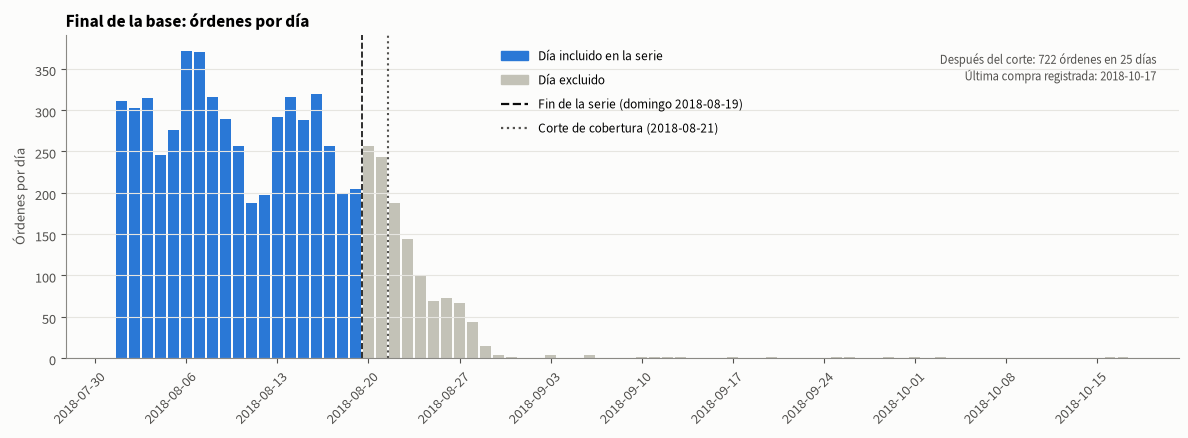

In [7]:
# Cola de la base: detalle diario desde el primer día del mes del corte hasta el último registro.
desde=str(pd.Timestamp(CORTE).replace(day=1).date())
cola=consultar(con,'cola.sql',[desde]); exportar(cola,'cobertura_final')
cola['fecha']=pd.to_datetime(cola.fecha)
con.register('cola',cola)
dias_tras,ordenes_tras,ultima=consultar(con,'resumen_cola.sql',[CORTE]).iloc[0]
print(f'\n■ Órdenes por día desde {desde}: caída de registros al final de la base')
print(f'  Justifica el corte de cobertura en {CORTE} y el fin de la serie en el domingo {FIN}.')
fig,ax=plt.subplots(figsize=(12,4.5))
ax.bar(cola.fecha,cola.ordenes,width=0.8,color=np.where(cola.fecha<=pd.Timestamp(FIN),'#2a78d6','#c3c2b7'))
# Las líneas van al final del día marcado (+12 h desde el centro de su barra).
ax.axvline(pd.Timestamp(FIN)+pd.Timedelta(hours=12),color='#0b0b0b',linestyle='--',linewidth=1.2)
ax.axvline(pd.Timestamp(CORTE)+pd.Timedelta(hours=12),color='#52514e',linestyle=':',linewidth=1.5)
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))  # un tick por lunes
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
plt.setp(ax.get_xticklabels(),rotation=45,ha='right',rotation_mode='anchor')
ax.grid(axis='x',visible=False)
ax.text(0.98,0.95,f'Después del corte: {int(ordenes_tras):,} órdenes en {dias_tras} días\nÚltima compra registrada: {ultima:%Y-%m-%d}',
        transform=ax.transAxes,ha='right',va='top',fontsize=9,color='#52514e')
ax.set(title='Final de la base: órdenes por día',ylabel='Órdenes por día')
ax.legend(handles=[Patch(color='#2a78d6',label='Día incluido en la serie'),Patch(color='#c3c2b7',label='Día excluido'),
                   Line2D([],[],color='#0b0b0b',linestyle='--',label=f'Fin de la serie (domingo {FIN})'),
                   Line2D([],[],color='#52514e',linestyle=':',label=f'Corte de cobertura ({CORTE})')],
          frameon=False,loc='upper center')
figura('cobertura_final')

### 4.1 Dos fechas distintas: corte de cobertura y fin de la serie

**Lectura del gráfico.** Cada barra es un día desde el 1 de agosto de 2018. Hasta mediados de agosto se registran unas 250–350 órdenes por día, con el patrón semanal habitual (los fines de semana bajan). Desde el 22 de agosto la cifra cae día tras día (187, 144, 99…) hasta casi cero; en septiembre y octubre solo quedan compras aisladas. Las dos líneas verticales marcan decisiones diferentes, y conviene no confundirlas.

**Corte de cobertura (`CORTE` = 2018-08-21): hasta dónde confiamos en los datos.** Es una decisión de **calidad**. La caída final no se comporta como demanda real: es consistente con una base extraída antes de que se registraran todas las órdenes. El 2018-08-21 es el último día que consideramos completo; lo posterior se descarta porque tratarlo como demanda baja engañaría a los modelos.

**Fin de la serie (`FIN` = domingo 2018-08-19): dónde termina la serie que modelamos.** Es una decisión de **formato del pronóstico**. El corte cae en martes. Si la serie terminara ese día, los 28 días pronosticados irían de miércoles 22 de agosto a martes 18 de septiembre y las semanas quedarían partidas (miércoles a martes). Para planear por semanas calendario, la serie se recorta al **último domingo anterior o igual al corte**: el pronóstico final va del lunes 20 de agosto al domingo 16 de septiembre, cuatro semanas completas de **lunes a domingo**. Por la misma razón, todos los orígenes de selección, calibración y prueba (`src/configuracion.py`) son domingos.

**¿Por qué domingo?** Porque cerrar la historia el domingo hace que cada pronóstico empiece un lunes, que es como Olist organizaría la operación semanal; además coincide con las semanas ISO que usa `date_trunc('week')` en el EDA semanal.

| | Corte de cobertura | Fin de la serie |
|---|---|---|
| Fecha | martes 2018-08-21 | domingo 2018-08-19 |
| Pregunta que responde | ¿Hasta cuándo los registros están completos? | ¿Dónde termina la historia para que el pronóstico cubra semanas lunes–domingo? |
| Tipo de decisión | Calidad de los datos | Formato operativo del pronóstico |
| Cómo se fija | A mano en `src/configuracion.py`, tras inspeccionar la cola | Se calcula desde el corte: `corte − dayofweek(corte)` (SQL) |

**Relación entre ambas.** El corte manda: el fin de la serie nunca puede superarlo, como mucho coincide con él si el corte cae en domingo. El precio es pequeño: el 20 y el 21 de agosto son datos confiables que quedan fuera de la serie (las dos barras grises antes de la línea punteada), 2 días frente a 565. Si se cambiara el corte, `FIN` se recalcularía solo y seguiría cayendo en domingo.

## 5. Construir una observación por día mediante SQL

La consulta `serie_diaria.sql` genera todas las fechas entre los límites, cuenta compras por día y une ambas tablas. Dentro de este tramo, una fecha sin órdenes se representa con cero.

Completar el calendario es esencial: un rezago de siete filas debe representar siete días. Sin esa regularidad, una media móvil de siete filas podría cubrir más de una semana. Fuera del tramo seleccionado no convertimos automáticamente la ausencia de registros en cero.

**Corte en domingo.** La consulta recibe el **corte de cobertura** como parámetro (`?`) y aplica dentro de SQL la regla explicada en la sección 4.1: la serie termina en el **último domingo anterior o igual** al corte (`corte − dayofweek(corte)`, donde `dayofweek` vale 0 el domingo). Con el corte 2018-08-21 (martes), la serie llega al domingo 2018-08-19 y el pronóstico cubre semanas **lunes–domingo**.


■ Resumen de la serie diaria del período útil
  Corte de cobertura 2018-08-21; la serie termina el domingo 2018-08-19.


,desde,hasta,dia_final,dias,pedidos,minimo,maximo,dias_cero
0,2017-02-01,2018-08-19,Sunday,565,97091.0,35,1176,0


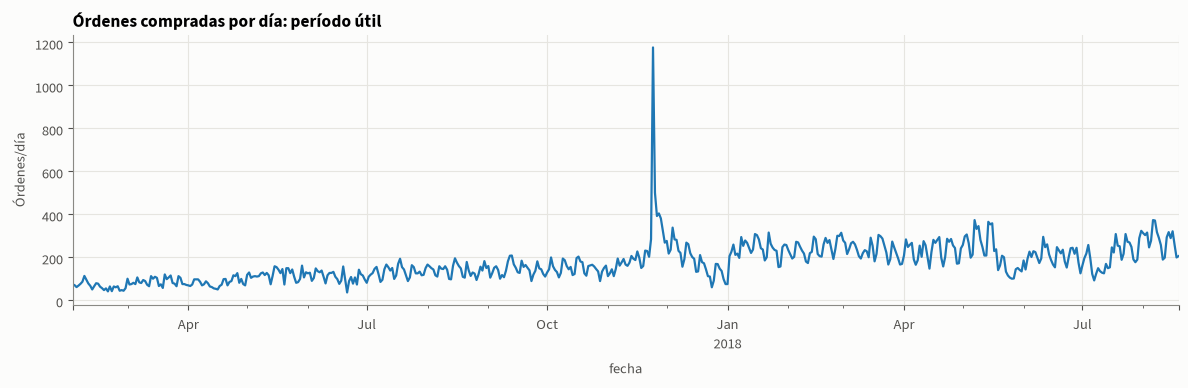

Un pico es una observación que debemos explicar; no se borra automáticamente.


In [8]:
# Las fechas se pasan como parámetros; no se concatenan dentro de la consulta.
# SQL recorta la serie al último domingo <= CORTE.
serie=consultar(con,'serie_diaria.sql',[INICIO,CORTE])
assert serie.fecha.is_unique and serie.y.ge(0).all()
assert serie.fecha.diff().dropna().eq(pd.Timedelta(days=1)).all()
assert serie.fecha.max()==pd.Timestamp(FIN) and serie.fecha.max().dayofweek==6  # termina en domingo
exportar(serie,'serie_diaria'); con.register('serie',serie)
resumen=consultar(con,'resumen_serie.sql')
mostrar(resumen,'Resumen de la serie diaria del período útil',
        f'Corte de cobertura {CORTE}; la serie termina el domingo {FIN}.')
exportar(resumen,'resumen_serie')
serie.plot(x='fecha',y='y',legend=False,title='Órdenes compradas por día: período útil')
plt.ylabel('Órdenes/día'); figura('serie_diaria')
print('Un pico es una observación que debemos explicar; no se borra automáticamente.')

**Lectura del gráfico.** Es la serie que se pronostica: órdenes compradas por día del 2017-02-01 al domingo 2018-08-19 (565 días, ninguno con cero órdenes). Se ven los cuatro rasgos que los modelos deben manejar:

- **Tendencia:** el nivel sube de unas 64 órdenes diarias en febrero de 2017 a unas 230–240 a comienzos de 2018, y después se estabiliza o baja levemente (unas 205 en junio y julio de 2018). La serie no es estacionaria en nivel.
- **Estacionalidad semanal:** el "serrucho" fino es la semana. De lunes a miércoles se compra más (unas 188–196 órdenes en promedio) y el sábado es el día más bajo (unas 132).
- **Black Friday (2017-11-24):** el pico aislado de **1.176 órdenes**, unas cinco veces un día normal, seguido de días altos (391–499). Es el único Black Friday del período útil, así que ningún modelo puede aprender su magnitud de un año anterior.
- **Huelga de camioneros (mayo de 2018):** entre el 23 y el 27 de mayo la serie cae a unas 100 órdenes diarias, aproximadamente la mitad de lo normal.

Los picos y caídas se conservan: son hechos reales del negocio y se tratan en los notebooks 01 y 02.

## 6. Exploración común: clientes, geografía y entregas

Estas tablas describen el contexto del negocio. Los tiempos de entrega se calculan solo donde existen las fechas necesarias, y los retrasos se miden en días calendario frente a la fecha estimada.

Los compradores recurrentes se cuentan mediante `customer_unique_id` (sección 3). La concentración geográfica describe dónde se compra, pero no demuestra por sí sola la causa de una variación temporal. Los atributos finales de entrega no entran al modelo de compras futuras.

In [9]:
# Lecturas, filtros, uniones y agregaciones de datos crudos permanecen en SQL.
for archivo,nombre,titulo,nota in [
    ('eda_entregas.sql','eda_entregas','Tiempos de entrega y proporción de órdenes tardías',
     'Solo órdenes entregadas; el retraso se mide en días calendario frente a la fecha estimada.'),
    ('eda_geografia.sql','eda_geografia','Registros de clientes y vendedores por estado',
     'customers cuenta customer_id (un registro por orden), no personas: la sección 6.1 usa customer_unique_id.'),
    ('eda_clientes.sql','eda_clientes','Clientes reales (customer_unique_id) según su número de compras',
     'Muestra cuántas personas compran una, dos o más veces.'),
    ('eda_semanal.sql','eda_semanal','Órdenes por semana en toda la base',
     'Cada semana inicia el lunes (date_trunc week), igual que las semanas de pronóstico.')]:
    tabla=consultar(con,archivo); mostrar(tabla,titulo,nota); exportar(tabla,nombre)


■ Tiempos de entrega y proporción de órdenes tardías
  Solo órdenes entregadas; el retraso se mide en días calendario frente a la fecha estimada.


,observaciones,media_dias_entrega,mediana_dias_entrega,p90_dias_entrega,proporcion_tarde,retraso_medio_dias
0,96470,12.496849,10.0,23.0,0.067731,-11.875889



■ Registros de clientes y vendedores por estado
  customers cuenta customer_id (un registro por orden), no personas: la sección 6.1 usa customer_unique_id.


,poblacion,estado,registros
0,clientes,SP,41746
1,clientes,RJ,12852
2,clientes,MG,11635
3,clientes,RS,5466
4,clientes,PR,5045
...,...,...,...
45,vendedores,AC,1
46,vendedores,AM,1
47,vendedores,PI,1
48,vendedores,PA,1



■ Clientes reales (customer_unique_id) según su número de compras
  Muestra cuántas personas compran una, dos o más veces.


,compras,clientes
0,1,93099
1,2,2745
2,3,203
3,4,30
4,5,8
5,6,6
6,7,3
7,9,1
8,17,1



■ Órdenes por semana en toda la base
  Cada semana inicia el lunes (date_trunc week), igual que las semanas de pronóstico.


,semana,ordenes
0,2016-08-29,1
1,2016-09-05,1
2,2016-09-12,2
3,2016-09-26,1
4,2016-10-03,283
...,...,...
96,2018-09-10,4
97,2018-09-17,2
98,2018-09-24,3
99,2018-10-01,2



■ Distribución del tiempo de entrega y del retraso (órdenes entregadas)


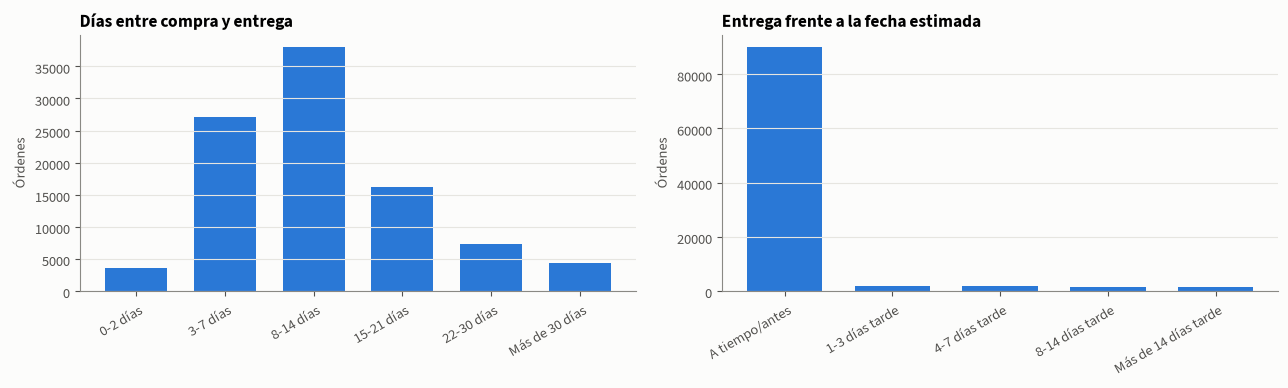

In [10]:
# Histogramas ya agrupados en SQL: tiempo de entrega (izquierda) y retraso frente a la fecha estimada (derecha).
distribuciones=consultar(con,'eda_distribuciones.sql'); exportar(distribuciones,'distribuciones_entrega')
print('\n■ Distribución del tiempo de entrega y del retraso (órdenes entregadas)')
fig,axes=plt.subplots(1,2,figsize=(13,4))
for eje,(tipo,g) in zip(axes,distribuciones.groupby('tipo',sort=False)):
    eje.bar(g.intervalo,g.ordenes,color='#2a78d6',width=0.7)
    eje.set_title({'Entrega':'Días entre compra y entrega','Retraso':'Entrega frente a la fecha estimada'}[tipo])
    eje.set_ylabel('Órdenes'); eje.grid(axis='x',visible=False)
    plt.setp(eje.get_xticklabels(),rotation=30,ha='right',rotation_mode='anchor')
figura('distribuciones_entrega')

**Lectura del gráfico.** Ambos histogramas usan las 96.470 órdenes entregadas con fecha de entrega registrada.

- **Tiempo de entrega (izquierda):** lo más común es recibir el pedido en **8 a 14 días** (39 % de las órdenes), seguido de 3 a 7 días (28 %). La mediana es 10 días y el 90 % llega en 23 días o menos. Hay una cola larga: unas 4.300 órdenes (4,5 %) tardan más de un mes.
- **Retraso (derecha):** el **93 %** llega a tiempo o antes de la fecha estimada; en promedio, unos 12 días antes. Olist promete plazos holgados. Solo el **6,8 %** llega tarde, y cuando ocurre suele ser un retraso serio: el 71 % de las tardías se pasa más de 3 días.

**Implicaciones.** Para el Módulo A, la clase "tarde" es minoritaria (alrededor de 7 %), así que la *accuracy* no sirve como métrica. Para nuestra serie (Módulo B), estos tiempos ocurren **después** de la compra y por eso no se usan como variables para pronosticar la demanda.

### 6.1 Geografía del cliente: dónde compran y qué tipo de cliente predomina

La tabla `customers` tiene un registro por orden; para hablar de **personas** agregamos por `customer_unique_id` (sección 3). Si alguien compró desde varios estados, se le asigna el de su compra más reciente. Solo se usan compras del período útil (las mismas fechas de la serie, pasadas como parámetros).

- **Mapa de Brasil.** La cartografía se dibuja con **geopandas** a partir de la malla de estados guardada en `recursos/brasil_uf.geojson`. Esa malla viene del IBGE o, si su servidor no responde, de una copia pública derivada; se descarga una sola vez con `scripts/descargar_mapa_brasil.py`. No son datos de Olist: es solo el mapa base sobre el que se pintan los resultados de las consultas SQL, y tenerla en el repositorio evita depender de internet al ejecutar.
- **Coordenadas de clientes.** `geolocation` tiene varias coordenadas por prefijo postal; se promedian por prefijo **antes** de unir, para no multiplicar filas, y se descartan coordenadas fuera de Brasil.
- **Segmentos descriptivos.** *Recurrente* (2 o más compras), *Única compra · gasto alto* (gasto ≥ percentil 75 de todos los clientes) y *Única compra · gasto bajo-medio*. Los pagos se suman por orden antes del cruce porque `order_payments` es 1:N. No es la segmentación del Módulo C: solo describe cómo se compone la demanda en cada zona.

Para la serie de tiempo esto importa porque la demanda total es una suma de regiones muy desiguales: lo que pase en la región dominante explica buena parte de los picos y caídas.

In [11]:
# SQL lee, une y agrega por prefijo, estado y región; pandas y matplotlib solo dan forma y dibujan.
import geopandas as gpd
from matplotlib.colors import LinearSegmentedColormap, LogNorm, Normalize
mapa=consultar(con,'eda_mapa_clientes.sql',[INICIO,FIN]); exportar(mapa,'eda_mapa_clientes')
segmentos=consultar(con,'eda_segmentos_region.sql',[INICIO,FIN]); exportar(segmentos,'eda_segmentos_region')
con.register('mapa',mapa); con.register('segmentos',segmentos)
por_region=consultar(con,'eda_segmentos_por_region.sql')
por_estado=consultar(con,'eda_clientes_por_estado.sql')
exportar(por_region,'eda_segmentos_por_region'); exportar(por_estado,'eda_clientes_por_estado')
mostrar(por_region,'Segmentos de clientes por región de Brasil',
        'pct_region = participación del segmento dentro de la región; gasto_promedio en BRL por cliente.')
mostrar(por_estado,'Clientes únicos, recurrencia, gasto alto y gasto promedio por estado',
        'Ordenado de mayor a menor número de clientes; pct_* en % de los clientes del estado.')

# Mapa base de Brasil (cartografía, no datos de Olist): ver scripts/descargar_mapa_brasil.py.
estados=gpd.read_file(ROOT/'recursos'/'brasil_uf.geojson')
azules=LinearSegmentedColormap.from_list('azules',['#cde2fb','#86b6ef','#2a78d6','#1c5cab','#0d366b'])
naranjas=LinearSegmentedColormap.from_list('naranjas',['#fde3d6','#f5a47f','#eb6834','#b84a1c','#7a2e0e'])

# Los estados pequeños no tienen espacio para su etiqueta: se escribe fuera, con una línea guía.
DESPLAZADOS={'RN':(3.0,1.2),'PB':(3.4,0.2),'PE':(3.6,-0.9),'AL':(3.2,-1.9),'SE':(2.8,-2.9),
             'ES':(3.0,0.2),'RJ':(2.8,-1.8),'DF':(-4.5,2.2)}
def etiquetar(eje,gdf,texto,color=lambda fila:'#0b0b0b',tamano=7):
    """Escribe una etiqueta por estado: dentro de la forma o, si es pequeña, desplazada con línea guía."""
    for fila in gdf.itertuples():
        p=fila.geometry.representative_point()
        if fila.estado in DESPLAZADOS:
            dx,dy=DESPLAZADOS[fila.estado]
            eje.annotate(texto(fila),(p.x,p.y),xytext=(p.x+dx,p.y+dy),ha='center',va='center',fontsize=tamano,
                         color='#0b0b0b',bbox=dict(boxstyle='round,pad=0.15',fc='white',ec='none',alpha=0.85),
                         arrowprops=dict(arrowstyle='-',color='#52514e',lw=0.6))
        else:
            eje.annotate(texto(fila),(p.x,p.y),ha='center',va='center',fontsize=tamano,color=color(fila))
    eje.set_xlim(-75,-29.5)  # deja espacio en el mar para las etiquetas desplazadas


■ Segmentos de clientes por región de Brasil
  pct_region = participación del segmento dentro de la región; gasto_promedio en BRL por cliente.


,region,segmento,clientes,pct_region,gasto_promedio
0,Centro-Oeste,Recurrente,169.0,3.1,273.82
1,Centro-Oeste,Única compra · gasto alto,1439.0,26.2,419.33
2,Centro-Oeste,Única compra · gasto bajo-medio,3891.0,70.8,92.69
3,Nordeste,Recurrente,225.0,2.5,386.80
4,Nordeste,Única compra · gasto alto,2842.0,31.6,422.57
5,Nordeste,Única compra · gasto bajo-medio,5935.0,65.9,98.60
6,Norte,Recurrente,50.0,2.8,351.50
7,Norte,Única compra · gasto alto,649.0,36.7,437.88
8,Norte,Única compra · gasto bajo-medio,1071.0,60.5,99.20
9,Sudeste,Recurrente,2039.0,3.2,302.45



■ Clientes únicos, recurrencia, gasto alto y gasto promedio por estado
  Ordenado de mayor a menor número de clientes; pct_* en % de los clientes del estado.


,estado,region,clientes,pct_recurrentes,pct_gasto_alto,gasto_promedio
0,SP,Sudeste,39171.0,3.20,19.6,149.02
1,RJ,Sudeste,12129.0,3.36,24.6,172.98
2,MG,Sudeste,10991.0,2.92,22.8,166.35
3,RS,Sul,5173.0,3.11,23.6,167.67
4,PR,Sul,4761.0,2.84,22.0,166.94
5,SC,Sul,3463.0,2.77,24.5,175.23
6,BA,Nordeste,3238.0,2.84,26.9,188.27
7,DF,Centro-Oeste,2035.0,2.95,24.0,170.49
8,ES,Sudeste,1937.0,2.94,23.3,164.47
9,GO,Centro-Oeste,1915.0,3.24,25.5,179.19



■ Mapa de Brasil: clientes únicos por prefijo postal (período útil)


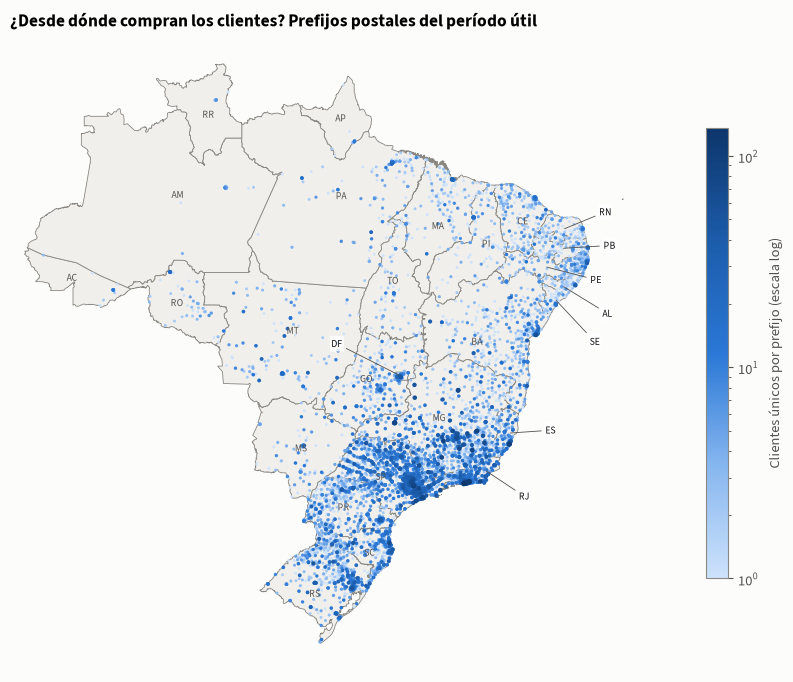

In [12]:
# Mapa de puntos: cada punto es un prefijo postal sobre las fronteras estatales;
# el color (escala logarítmica) indica cuántos clientes únicos compran desde allí.
print('\n■ Mapa de Brasil: clientes únicos por prefijo postal (período útil)')
fig,ax=plt.subplots(figsize=(8.5,8.5))
estados.plot(ax=ax,color='#f0efec',edgecolor='#898781',linewidth=0.6)
orden_pts=mapa.sort_values('clientes')  # los prefijos con más clientes quedan encima
puntos=ax.scatter(orden_pts.lng,orden_pts.lat,c=orden_pts.clientes,s=3+orden_pts.clientes**0.5,
                  cmap=azules,norm=LogNorm(),linewidths=0)
etiquetar(ax,estados,lambda fila:fila.estado,color=lambda fila:'#52514e')
ax.set_axis_off()
ax.set_title('¿Desde dónde compran los clientes? Prefijos postales del período útil')
fig.colorbar(puntos,ax=ax,shrink=0.55,label='Clientes únicos por prefijo (escala log)')
figura('mapa_clientes')

**Lectura del mapa.** Cada punto es un prefijo postal desde el que compró al menos un cliente en el período útil; cuanto más oscuro y grande, más clientes.

- La demanda se concentra en el **Sudeste y el Sur**: el estado de São Paulo, en especial su área metropolitana, la costa de Río de Janeiro, el sur de Minas Gerais y la franja costera de Paraná, Santa Catarina y Rio Grande do Sul.
- En el **Nordeste** los clientes se agrupan en la costa, alrededor de las capitales (Fortaleza, Recife, Salvador). El interior es mucho más disperso.
- El **Norte** y el interior del **Centro-Oeste** están casi vacíos, salvo puntos aislados como Manaus, Belém y Brasilia (DF).

Olist atiende todo el país, pero su volumen sale de una franja costera del Sudeste y el Sur. Para la serie diaria, eso significa que lo que ocurra en esa zona (festivos locales, problemas logísticos, campañas) mueve la demanda total.


■ Mapas por estado: volumen de clientes y peso del segmento de gasto alto


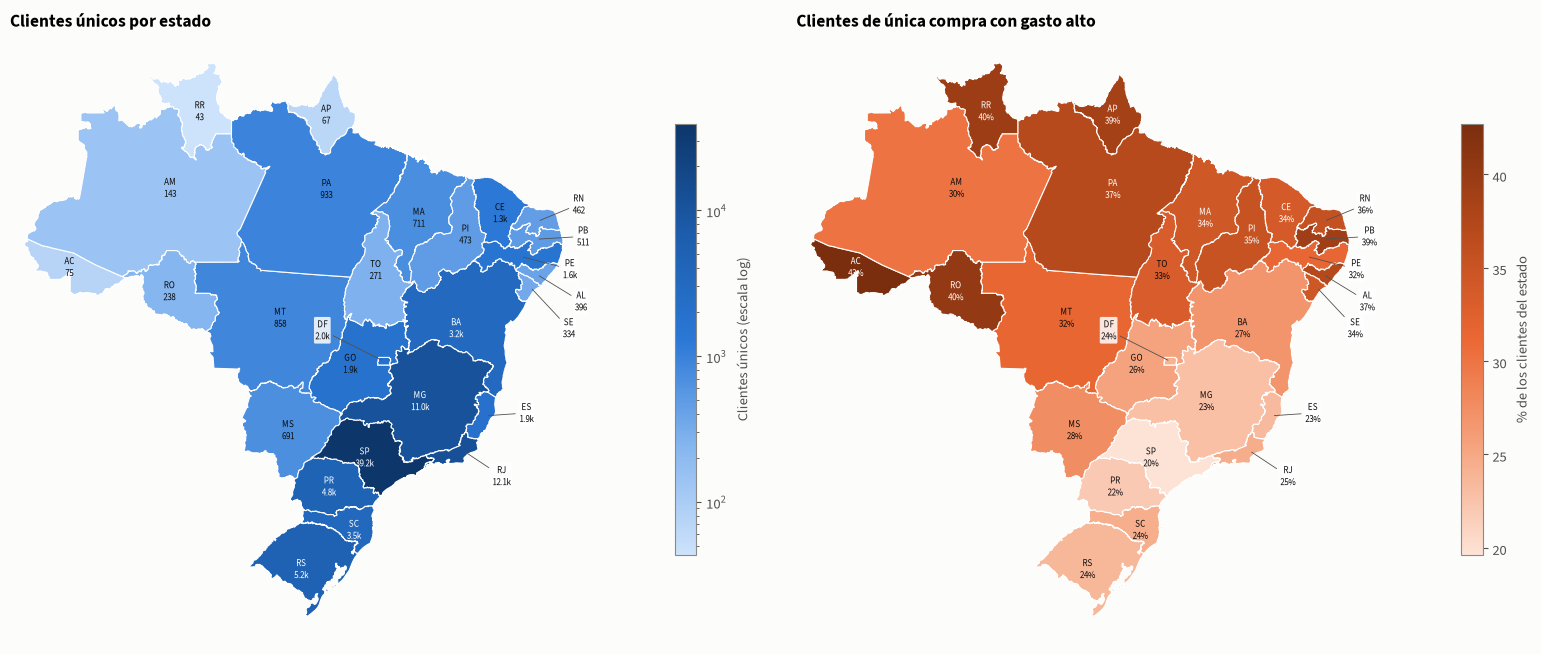

In [13]:
# Mapas por estado (coropletas): solo se pegan a cada forma los resultados ya calculados en SQL.
print('\n■ Mapas por estado: volumen de clientes y peso del segmento de gasto alto')
mapa_estados=estados.merge(por_estado,on='estado',how='left')
fig,axes=plt.subplots(1,2,figsize=(16,7.5))
paneles=[('clientes',azules,LogNorm(vmin=mapa_estados.clientes.min(),vmax=mapa_estados.clientes.max()),
          'Clientes únicos por estado','Clientes únicos (escala log)',lambda v:f'{v/1000:.1f}k' if v>=1000 else f'{v:.0f}'),
         ('pct_gasto_alto',naranjas,Normalize(vmin=mapa_estados.pct_gasto_alto.min(),vmax=mapa_estados.pct_gasto_alto.max()),
          'Clientes de única compra con gasto alto','% de los clientes del estado',lambda v:f'{v:.0f}%')]
for eje,(columna,cmap,norma,titulo,etiqueta,formato) in zip(axes,paneles):
    mapa_estados.plot(column=columna,cmap=cmap,norm=norma,ax=eje,edgecolor='white',linewidth=0.8)
    # Texto blanco sobre los tonos más oscuros para conservar el contraste.
    etiquetar(eje,mapa_estados,lambda fila,c=columna,f=formato:f'{fila.estado}\n{f(getattr(fila,c))}',
              color=lambda fila,c=columna,n=norma:'white' if n(getattr(fila,c))>0.6 else '#0b0b0b',tamano=6.5)
    fig.colorbar(plt.cm.ScalarMappable(norm=norma,cmap=cmap),ax=eje,shrink=0.6,label=etiqueta)
    eje.set_axis_off(); eje.set_title(titulo)
figura('mapa_estados')

**Lectura de los mapas por estado.**

- **Clientes únicos (izquierda, escala logarítmica):** São Paulo tiene 39.200 clientes, el 42 % del total; con Río de Janeiro (12.100) y Minas Gerais (11.000) suma alrededor de dos tercios. En el extremo opuesto, los estados del Norte tienen menos de mil clientes cada uno (Roraima, 43). La escala es logarítmica porque São Paulo tiene unas 900 veces más clientes que Roraima; con escala lineal, casi todo el mapa se vería del mismo color claro.
- **Gasto alto en una sola compra (derecha):** el mapa casi se invierte. São Paulo tiene la menor proporción de clientes de gasto alto (20 %), el Sur y el resto del Sudeste rondan el 22–25 %, el Nordeste sube al 27–39 % y el Norte llega al 30–43 % (Acre, 43 %; Rondônia y Roraima, 40 %). A mayor distancia del Sudeste, más caras son las compras.

**Interpretación (hipótesis, no causa demostrada).** El gasto incluye el flete. Como la mayoría de los vendedores está en el Sudeste, enviar a estados lejanos cuesta más, y es razonable que allí se compre en línea sobre todo lo que no se consigue localmente, que suele ser más caro. El Módulo A podría aprovechar la distancia y el estado de destino como variables; para el Módulo B, la demanda de alto valor viene de regiones con poco volumen, así que pesa poco en el conteo diario de órdenes.


■ Clientes por estado y composición de segmentos por región


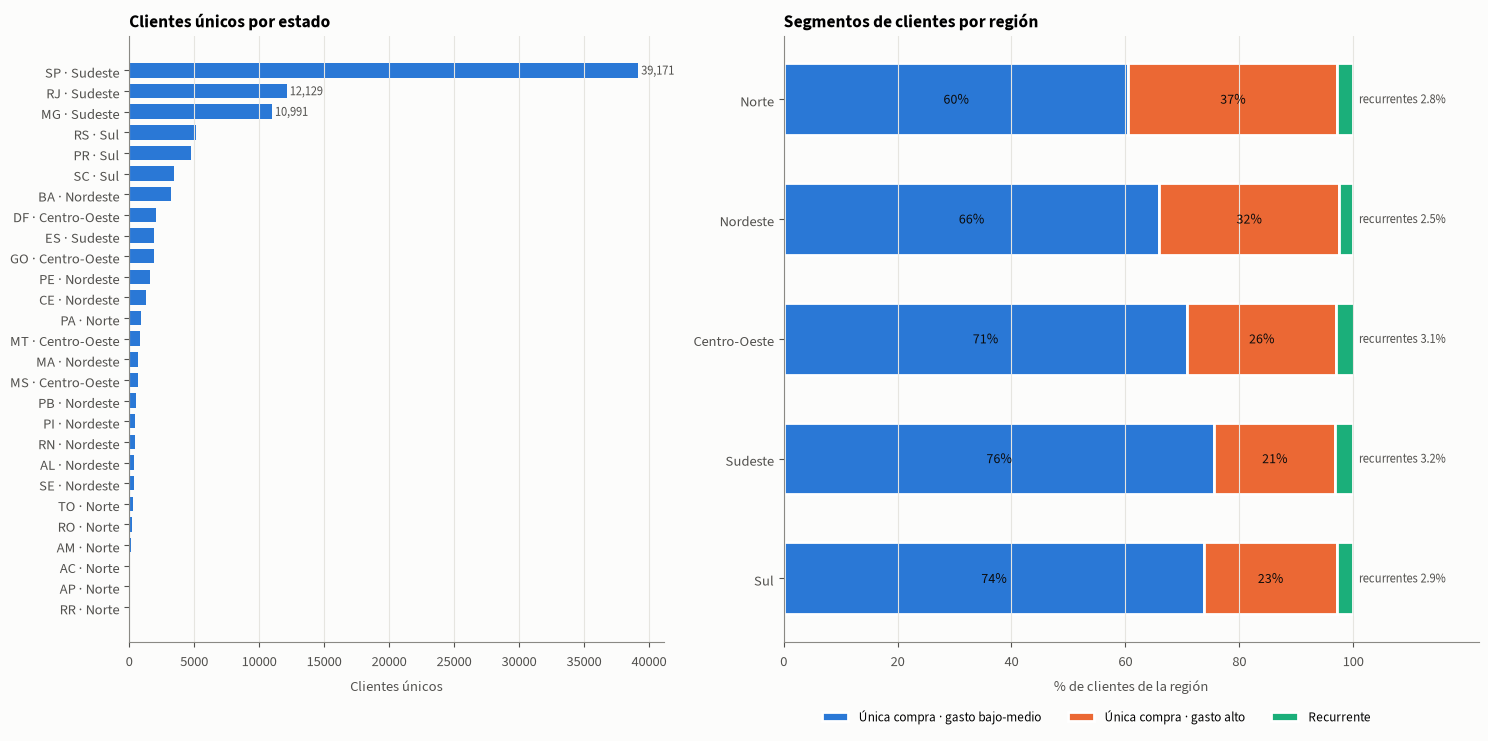

In [14]:
# Barras: volumen por estado (izquierda) y composición de segmentos por región (derecha, 100 %).
print('\n■ Clientes por estado y composición de segmentos por región')
nombres=['Única compra · gasto bajo-medio','Única compra · gasto alto','Recurrente']
colores=['#2a78d6','#eb6834','#1baf7a']
regiones=['Sul','Sudeste','Centro-Oeste','Nordeste','Norte']  # de sur a norte: Norte queda arriba
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(15,7.5),gridspec_kw={'width_ratios':[1,1.3]})
orden=por_estado.sort_values('clientes')
ax1.barh(orden.estado+' · '+orden.region,orden.clientes,color='#2a78d6',height=0.7)
for y_,v in list(enumerate(orden.clientes))[-3:]:
    ax1.text(v,y_,f' {v:,.0f}',va='center',fontsize=9,color='#52514e')
ax1.set(title='Clientes únicos por estado',xlabel='Clientes únicos'); ax1.grid(axis='y',visible=False)
tabla=por_region.pivot(index='region',columns='segmento',values='pct_region').reindex(regiones)[nombres]
izquierda=np.zeros(len(tabla))
for nombre,color in zip(nombres,colores):
    ancho=tabla[nombre].to_numpy()
    ax2.barh(tabla.index,ancho,left=izquierda,color=color,edgecolor='white',linewidth=2,height=0.6,label=nombre)
    for y_,(x0,w) in enumerate(zip(izquierda,ancho)):
        if w>=6: ax2.text(x0+w/2,y_,f'{w:.0f}%',ha='center',va='center',fontsize=10,color='#0b0b0b')
    izquierda+=ancho
for y_,pct in enumerate(tabla['Recurrente']):
    ax2.text(101,y_,f'recurrentes {pct:.1f}%',va='center',fontsize=9,color='#52514e')
ax2.set(xlim=(0,122),xticks=range(0,101,20),xlabel='% de clientes de la región',title='Segmentos de clientes por región')
ax2.grid(axis='y',visible=False)
ax2.legend(loc='upper center',bbox_to_anchor=(0.45,-0.09),ncol=3,frameon=False)
figura('segmentos_region')
con.close()

**Lectura del gráfico.**

- **Clientes por estado (izquierda):** confirma la concentración del mapa. São Paulo (39.171), Río de Janeiro (12.129) y Minas Gerais (10.991) dominan; el Sudeste reúne el **68 %** de los clientes únicos del período útil.
- **Segmentos por región (derecha, cada barra suma 100 %):** en todas las regiones la mayoría son clientes de una sola compra con gasto bajo o medio, pero su peso baja del 76 % en el Sudeste al 60 % en el Norte. El segmento de gasto alto hace lo contrario: 21 % en el Sudeste, 32 % en el Nordeste y 37 % en el Norte. Los **recurrentes** son pocos en todas partes (2,5–3,2 %).

**Implicaciones.** La recurrencia baja y pareja indica que la demanda de Olist depende de **captar compradores nuevos**, no de la repetición. Para el Módulo C, la frecuencia separará poco a los clientes y la región y el valor de compra separarán más. Para nuestra serie, el comportamiento del Sudeste determina la mayor parte de la demanda diaria.

## 7. Comprobar que entendimos

**¿Por qué no usamos solamente órdenes entregadas?** Porque su estado final depende de hechos posteriores a la compra y definiría otro objetivo: compras que terminaron entregadas.

**¿Por qué un pago faltante no obliga a borrar una compra?** Porque estamos contando órdenes registradas con fecha válida, no calculando ingresos cobrados.

**¿Por qué no se cuentan clientes con `customer_id`?** Porque cada `customer_id` corresponde a una sola orden: contar por esa llave daría 99.441 "clientes" en lugar de 96.096 personas y haría que nadie pareciera recurrente.

**¿Por qué la serie termina el 19 de agosto si los datos son confiables hasta el 21?** Porque son dos decisiones distintas: el corte de cobertura (21) dice hasta dónde los registros están completos; el fin de la serie (domingo 19) se elige dentro de ese límite para que cada pronóstico cubra semanas completas de lunes a domingo.

**¿Qué sale de este notebook?** Una serie diaria regular, una decisión de cobertura explícita, un inventario de calidad y una descripción del cliente y su geografía. Todavía no hemos elegido un modelo ni atribuido causas a los picos.